# Landsat8 and RS latest RD plots
This notebook reads the full-test CSV rather than copying tuples by hand. If the 600-epoch Landsat8 final table exists and contains seven 1700-image Hybrid points, it is selected automatically.

In [1]:
from pathlib import Path
import sys
RESULTS = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RESULTS))
from plot_landsat8_rs_latest import (
    load_latest_results, hybrid_tuples, calculate_bd_rate_vs_elic,
    plot_publication_grid,
)
data, source = load_latest_results()
print('Data source:', source)

Data source: committed full-test CSV (Landsat8 400 epochs; RS completed run)


In [2]:
for dataset in ('landsat8', 'rs'):
    print(f'\n{dataset}_hybrid_parallel = [')
    for row in hybrid_tuples(data, dataset):
        print(f'    {row},')
    print(']')


landsat8_hybrid_parallel = [
    (0.068875, 39.702435, 16.082222),
    (0.127688, 40.96772, 17.683325),
    (0.200007, 42.235068, 19.291599),
    (0.336195, 43.727045, 21.203273),
    (0.53543, 45.289123, 23.123466),
    (0.809058, 46.790016, 24.96105),
    (1.145993, 48.121119, 26.59016),
]

rs_hybrid_parallel = [
    (0.194472, 51.45422, 26.900432),
    (0.325567, 52.861376, 28.63303),
    (0.503278, 54.197101, 30.279471),
    (0.77177, 55.637307, 32.079613),
    (0.971025, 56.447463, 33.065146),
    (1.056348, 56.814048, 33.572914),
]


In [3]:
bd_rate_vs_elic = calculate_bd_rate_vs_elic(data)
display(
    bd_rate_vs_elic[
        ['dataset', 'reference', 'method',
         'bd_rate_psnr_percent', 'bd_rate_ms_ssim_percent']
    ].round(3)
)

,dataset,reference,method,bd_rate_psnr_percent,bd_rate_ms_ssim_percent
0,landsat8,ELIC,ELIC,0.000,0.000
1,landsat8,ELIC,FTIC,-24.710,-22.672
2,landsat8,ELIC,HL,-29.051,-31.337
3,landsat8,ELIC,HPCM,-17.585,-14.595
4,landsat8,ELIC,Hybrid-Parallel,-13.812,-10.389
5,landsat8,ELIC,MLIC,-21.172,-16.861
6,landsat8,ELIC,Our,-29.642,-25.193
7,landsat8,ELIC,RWK,-15.345,-15.633
8,rs,ELIC,ELIC,0.000,0.000
9,rs,ELIC,FTIC,-9.058,-11.578


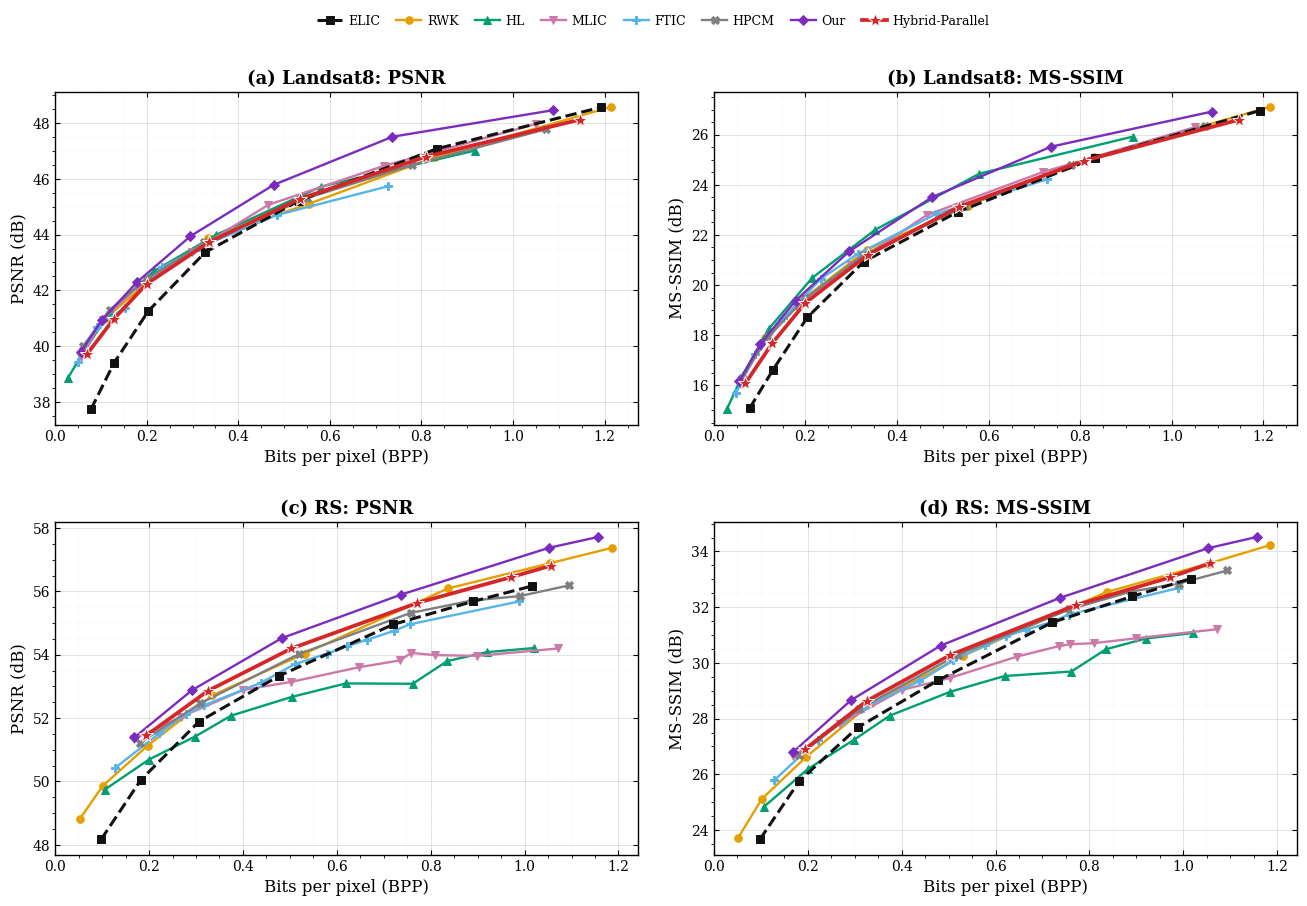

In [4]:
plot_publication_grid(data, show=True)